# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Febrian Pratama Saputra
- **Email:** febrianpratamasaputra9@gmail.com
- **ID Dicoding:** febrian_pratama_yaep

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Pertanyaan 1:** Bagaimana perbedaan pola rata-rata penyewaan sepeda per jam (*hourly demand*) antara pengguna kasual (*casual*) dan pengguna terdaftar (*registered*) pada hari kerja (*workingday*) dibandingkan akhir pekan/hari libur selama periode Januari 2011 hingga Desember 2012, serta pada jam berapa saja puncak permintaan tertinggi terjadi untuk mengoptimalkan jadwal distribusi armada sepeda?
  - **Specific:** Berfokus pada perbandingan pola permintaan penyewaan sepeda per jam antara dua segmen pengguna (`casual` dan `registered`) berdasarkan kategori hari (`workingday` vs akhir pekan/hari libur) serta identifikasi jam puncak (*peak hours*).
  - **Measurable:** Dihitung secara konkret menggunakan metrik rata-rata jumlah penyewaan sepeda per jam (`casual`, `registered`, dan `cnt`) beserta proporsinya.
  - **Action-Oriented:** Memberikan dasar penentuan jadwal operasional *rebalancing* (distribusi ulang armada sepeda ke stasiun-stasiun padat) sebelum jam sibuk dimulai dan penentuan waktu promosi konversi pengguna kasual menjadi anggota terdaftar.
  - **Relevant:** Mendukung efisiensi operasional ketersediaan armada dan peningkatan retensi pelanggan pada bisnis penyewaan sepeda.
  - **Time-bound:** Dibatasi pada rentang waktu observasi **Januari 2011 hingga Desember 2012** dalam siklus **24 jam (pukul 00.00–23.00)**.

**Pertanyaan 2:** Seberapa besar selisih dan persentase penurunan rata-rata volume penyewaan sepeda harian (`cnt`) akibat perubahan kondisi cuaca (*weathersit*) dan pergantian musim (*season*) sepanjang tahun 2011 hingga 2012, guna menentukan waktu optimal pelaksanaan pemeliharaan rutin (*maintenance*) dan penyesuaian kapasitas armada?
  - **Specific:** Mengukur dampak langsung faktor eksternal berupa kategori kondisi cuaca (`weathersit`) dan empat musim (`season`) terhadap volume penyewaan sepeda harian (`cnt`).
  - **Measurable:** Dijawab melalui angka rata-rata penyewaan harian (`cnt`) serta selisih dan persentase penurunan volume penyewaan antar-kondisi cuaca maupun antar-musim.
  - **Action-Oriented:** Mengarahkan tim operasional untuk menjadwalkan servis atau pemeliharaan besar armada pada musim dan kondisi cuaca dengan permintaan terendah, serta menyiagakan kapasitas penuh pada musim dengan permintaan tertinggi.
  - **Relevant:** Membantu menekan biaya operasional saat *low season* sekaligus memaksimalkan potensi pendapatan saat *peak season*.
  - **Time-bound:** Dibatasi pada data historis penyewaan harian sepanjang **tahun 2011 hingga 2012**.

## Import Semua Packages/Library yang Digunakan

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tampilan visualisasi agar lebih rapi
sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data
Tahap **Gathering Data** bertujuan untuk memuat seluruh dataset yang dibutuhkan (`day.csv` dan `hour.csv`) ke dalam format Pandas DataFrame (`day_df` dan `hour_df`) serta menampilkan beberapa baris awal guna memastikan struktur dan isi data terbaca dengan benar.

#### Load Data day_df dan hour_df

In [38]:
# Memuat dataset harian (day.csv) dan per jam (hour.csv)
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

# Menampilkan 5 baris pertama dari masing-masing DataFrame
print("=== Dataset Harian (day_df) ===")
display(day_df.head())

print("\n=== Dataset Per Jam (hour_df) ===")
display(hour_df.head())

=== Dataset Harian (day_df) ===


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



=== Dataset Per Jam (hour_df) ===


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
* **Kelengkapan & Dimensi Data:** Dataset berhasil dimuat ke dalam dua DataFrame, yaitu `day_df` (731 baris dan 16 kolom) yang merekam agregasi penyewaan sepeda harian selama 2 tahun penuh (1 Januari 2011 – 31 Desember 2012), serta `hour_df` (17.379 baris dan 17 kolom) yang merekam transaksi pada tingkat per jam.
* **Perbedaan Struktur Kolom:** Kedua DataFrame memiliki atribut waktu, cuaca, dan jumlah penyewa yang identik (`casual`, `registered`, dan `cnt`), dengan satu kolom pembeda pada `hour_df`, yakni kolom `hr` (jam ke-0 hingga ke-23).
* **Kondisi Nilai Awal:** Nilai variabel meteorologi (`temp`, `atemp`, `hum`, `windspeed`) sudah tersimpan dalam bentuk skala terstandarisasi/normalisasi, sedangkan atribut kategorikal seperti musim (`season`), tahun (`yr`), hari kerja (`workingday`), dan cuaca (`weathersit`) masih direpresentasikan dalam bentuk kode numerik.

### Assessing Data
Tahap **Assessing Data** bertujuan untuk memeriksa kualitas dan integritas data pada `day_df` maupun `hour_df`, meliputi pemeriksaan tipe data, *missing values*, data duplikat, konsistensi nilai antar-kolom, serta anomali atau nilai tidak akurat sebelum melangkah ke tahap pembersihan data (*Cleaning Data*).

#### Identifying Data Quality Problems (day_df dan hour_df)

In [39]:
# 1. Memeriksa informasi struktur dan tipe data
print("=== Info day_df ===")
day_df.info()
print("\n=== Info hour_df ===")
hour_df.info()

# 2. Memeriksa missing values dan data duplikat
print("\n=== Missing Values & Duplikat ===")
print("Missing values day_df :", day_df.isna().sum().sum())
print("Duplikat day_df       :", day_df.duplicated().sum())
print("Missing values hour_df:", hour_df.isna().sum().sum())
print("Duplikat hour_df      :", hour_df.duplicated().sum())

# 3. Memeriksa ringkasan statistik untuk mendeteksi anomali / nilai tidak akurat
print("\n=== Ringkasan Statistik day_df ===")
display(day_df.describe())
print("\n=== Ringkasan Statistik hour_df ===")
display(hour_df.describe())

# 4. Memeriksa detail baris dengan nilai kelembapan (hum) == 0 dan konsistensi penjumlahan
print("Jumlah baris hum == 0 pada day_df :", (day_df["hum"] == 0).sum())
print("Jumlah baris hum == 0 pada hour_df:", (hour_df["hum"] == 0).sum())
display(day_df[day_df["hum"] == 0][["instant", "dteday", "weathersit", "temp", "hum", "windspeed", "cnt"]])

print("Inkonsistensi (casual + registered != cnt) day_df :", (day_df["casual"] + day_df["registered"] != day_df["cnt"]).sum())
print("Inkonsistensi (casual + registered != cnt) hour_df:", (hour_df["casual"] + hour_df["registered"] != hour_df["cnt"]).sum())

=== Info day_df ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 91.5 KB

=== Info hour_df ===
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
D

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000



=== Ringkasan Statistik hour_df ===


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


Jumlah baris hum == 0 pada day_df : 1
Jumlah baris hum == 0 pada hour_df: 22


,instant,dteday,weathersit,temp,hum,windspeed,cnt
68,69,2011-03-10,3,0.389091,0.0,0.261877,623


Inkonsistensi (casual + registered != cnt) day_df : 0
Inkonsistensi (casual + registered != cnt) hour_df: 0


**Steps to Take:**
* Mengonversi tipe data kolom `dteday` dari `object` menjadi `datetime` pada `day_df` dan `hour_df`.
* Mengubah representasi kode numerik pada kolom kategorikal (`season`, `yr`, `mnth`, `weekday`, `workingday`, dan `weathersit`) menjadi label deskriptif agar mudah dipahami pada tahap eksplorasi dan visualisasi.
* Memperbaiki nilai tidak akurat (*inaccurate value*) pada kolom kelembapan udara (`hum == 0.0`) pada tanggal `2011-03-10` dengan melakukan imputasi nilai median berdasarkan kelompok kondisi cuaca (`weathersit`) yang sama.
* Menghapus kolom `instant` pada kedua DataFrame karena hanya berfungsi sebagai nomor urut indeks dan tidak relevan untuk analisis bisnis.

**Insight:** (Opsional)
* **Tidak Ada Missing Value Eksplisit & Duplikasi:** Baik `day_df` maupun `hour_df` memiliki 0 *missing value* (`NaN`) eksplisit dan 0 baris duplikat, serta penjumlahan `casual + registered == cnt` konsisten 100% di seluruh baris.
* **Permasalahan 1 — Tipe Data Tidak Sesuai (*Incorrect Data Types*):** Kolom `dteday` masih bertipe `object` (string), sedangkan atribut kategorikal seperti `season`, `yr`, `mnth`, `weekday`, `workingday`, dan `weathersit` masih disimpan dalam bentuk kode bilangan bulat (`int64`).
* **Permasalahan 2 — Nilai Tidak Akurat (*Inaccurate Value*):** Ditemukan nilai minimum kelembapan udara (`hum`) sebesar `0.0` pada tanggal `2011-03-10` (1 baris pada `day_df` dan 22 baris pada `hour_df`), padahal kondisi cuaca saat itu tercatat mendung (`2`) dan hujan ringan/salju (`3`). Nilai `0%` ini secara meteorologis mustahil terjadi dan teridentifikasi sebagai anomali/kegagalan sensor.
* **Permasalahan 3 — Kolom Redundan (*Redundant Column*):** Kolom `instant` hanya mereplikasi nomor urut indeks baris sehingga dapat dibuang untuk merampingkan struktur data.

### Cleaning Data
Tahap **Cleaning Data** bertujuan untuk mengatasi seluruh permasalahan kualitas data yang ditemukan pada tahap *Assessing Data*, yakni menghapus kolom yang tidak relevan, memperbaiki tipe data tanggal, melakukan imputasi pada nilai kelembapan udara (`hum`) yang tidak akurat, serta mengubah kode numerik variabel kategorikal menjadi label deskriptif agar siap dianalisis.

#### Fixing Data Types, Inaccurate Values, and Categorical Labels

In [40]:
# 1. Menghapus kolom 'instant' karena hanya berupa indeks baris
day_df = day_df.drop(columns=["instant"])
hour_df = hour_df.drop(columns=["instant"])

# 2. Mengonversi tipe data kolom 'dteday' menjadi datetime
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# 3. Memperbaiki nilai tidak akurat (hum == 0) dengan imputasi median per kondisi cuaca (weathersit)
for df in [day_df, hour_df]:
    df["hum"] = df["hum"].replace(0, np.nan)
    df["hum"] = df["hum"].fillna(df.groupby("weathersit")["hum"].transform("median"))

# 4. Mengubah kode numerik pada kolom kategorikal menjadi label yang deskriptif
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
yr_map = {0: 2011, 1: 2012}
mnth_map = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
    7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"
}
weekday_map = {
    0: "Sunday", 1: "Monday", 2: "Tuesday", 3: "Wednesday",
    4: "Thursday", 5: "Friday", 6: "Saturday"
}
workingday_map = {0: "Weekend/Holiday", 1: "Working Day"}
weathersit_map = {
    1: "Clear/Partly Cloudy",
    2: "Mist/Cloudy",
    3: "Light Rain/Snow",
    4: "Heavy Rain/Snow"
}

for df in [day_df, hour_df]:
    df["season"] = df["season"].map(season_map)
    df["yr"] = df["yr"].map(yr_map)
    df["mnth"] = df["mnth"].map(mnth_map)
    df["weekday"] = df["weekday"].map(weekday_map)
    df["workingday"] = df["workingday"].map(workingday_map)
    df["weathersit"] = df["weathersit"].map(weathersit_map)

# 5. Memverifikasi hasil pembersihan data
print("=== Verifikasi Struktur & Tipe Data Setelah Cleaning (day_df) ===")
day_df.info()
print("\nJumlah nilai hum == 0 pada day_df :", (day_df["hum"] == 0).sum())
print("Jumlah nilai hum == 0 pada hour_df:", (hour_df["hum"] == 0).sum())
display(day_df.head(3))

=== Verifikasi Struktur & Tipe Data Setelah Cleaning (day_df) ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      731 non-null    datetime64[us]
 1   season      731 non-null    str           
 2   yr          731 non-null    int64         
 3   mnth        731 non-null    str           
 4   holiday     731 non-null    int64         
 5   weekday     731 non-null    str           
 6   workingday  731 non-null    str           
 7   weathersit  731 non-null    str           
 8   temp        731 non-null    float64       
 9   atemp       731 non-null    float64       
 10  hum         731 non-null    float64       
 11  windspeed   731 non-null    float64       
 12  casual      731 non-null    int64         
 13  registered  731 non-null    int64         
 14  cnt         731 non-null    int64         
dtypes: datetime64[us](1

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,2011-01-01,Spring,2011,Jan,0,Saturday,Weekend/Holiday,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2011-01-02,Spring,2011,Jan,0,Sunday,Weekend/Holiday,Mist/Cloudy,0.363478,0.353739,0.696087,0.248539,131,670,801
2,2011-01-03,Spring,2011,Jan,0,Monday,Working Day,Clear/Partly Cloudy,0.196364,0.189405,0.437273,0.248309,120,1229,1349


**Insight:** (Opsional)
* **Struktur & Tipe Data Sudah Valid:** Kolom `instant` berhasil dihapus dari kedua DataFrame (`day_df` kini memiliki 15 kolom dan `hour_df` memiliki 16 kolom), serta kolom `dteday` telah terkonversi menjadi tipe `datetime64[ns]` untuk memudahkan analisis deret waktu (*time-series*).
* **Anomali Kelembapan Udara Teratasi:** Seluruh catatan dengan nilai `hum == 0.0` pada tanggal `2011-03-10` (1 baris pada `day_df` dan 22 baris pada `hour_df`) telah berhasil diimputasi menggunakan nilai median kelembapan berdasarkan kategori cuacanya (menjadi `0.8918` pada `day_df` dan `0.87` / `0.71` pada `hour_df` sesuai kondisi cuaca tiap jam), sehingga tidak ada lagi nilai kelembapan `0%`.
* **Keterbacaan Variabel Kategorikal Meningkat:** Seluruh kode numerik pada `season`, `yr`, `mnth`, `weekday`, `workingday`, dan `weathersit` telah berubah menjadi label teks yang jelas dan konsisten di kedua DataFrame.

## Exploratory Data Analysis (EDA)

### Explore Pola Penyewaan Per Jam, Dampak Cuaca & Musim, serta Clustering Karakteristik Permintaan

Tahap **Exploratory Data Analysis (EDA)** bertujuan untuk menggali pola statistik dan melakukan agregasi data (`groupby`) guna menjawab kedua pertanyaan bisnis:
1. **Eksplorasi Pola Per Jam & Segmen Pengguna:** Menganalisis rata-rata penyewaan per jam (`hr`) antara pengguna `casual` dan `registered` berdasarkan kategori hari (`Working Day` vs `Weekend/Holiday`).
2. **Eksplorasi Pengaruh Cuaca & Musim:** Menghitung rata-rata, median, selisih, dan persentase perubahan volume penyewaan harian (`cnt`) pada setiap kondisi cuaca (`weathersit`) dan musim (`season`).
3. **Analisis Lanjutan — Clustering (Tanpa Machine Learning):**
   * **Manual Grouping:** Mengelompokkan jam operasional (00.00–23.00) ke dalam 4 klaster aktivitas (*Morning Commute*, *Midday/Leisure*, *Evening Commute*, dan *Night/Off-Peak*) berdasarkan aturan domain transportasi komuter.
   * **Binning:** Membagi volume penyewaan harian (`cnt`) ke dalam 3 kuantil tingkat permintaan (*Low Demand*, *Medium Demand*, dan *High Demand*) menggunakan `pd.qcut()` untuk mengidentifikasi profil suhu dan kelembapan pada tiap klaster permintaan.

In [41]:
# 1. Ringkasan Proporsi Segmen Pengguna & Pertumbuhan Tahunan (2011 vs 2012)
total_cnt = day_df["cnt"].sum()
total_casual = day_df["casual"].sum()
total_registered = day_df["registered"].sum()

print(f"Total Penyewaan (2011-2012): {total_cnt:,}")
print(f"Pengguna Casual            : {total_casual:,} ({total_casual / total_cnt * 100:.2f}%)")
print(f"Pengguna Registered        : {total_registered:,} ({total_registered / total_cnt * 100:.2f}%)")

yr_summary = day_df.groupby("yr").agg(
    jumlah_hari=("cnt", "count"),
    total_sewa=("cnt", "sum"),
    rata_rata_harian=("cnt", "mean"),
    rata_rata_casual=("casual", "mean"),
    rata_rata_registered=("registered", "mean")
).round(2)
print("\n=== Ringkasan Pertumbuhan Tahunan (2011 vs 2012) ===")
display(yr_summary)

# 2. Eksplorasi Pertanyaan 1: Pola Penyewaan Per Jam berdasarkan Kategori Hari
hourly_pattern = hour_df.groupby(["workingday", "hr"])[["casual", "registered", "cnt"]].mean().round(2)

print("\n=== Top 5 Jam Puncak pada Working Day ===")
display(hourly_pattern.loc["Working Day"].sort_values(by="cnt", ascending=False).head(5))

print("\n=== Top 5 Jam Puncak pada Weekend/Holiday ===")
display(hourly_pattern.loc["Weekend/Holiday"].sort_values(by="cnt", ascending=False).head(5))

# 3. Eksplorasi Pertanyaan 2: Dampak Kondisi Cuaca & Musim terhadap Penyewaan Harian
weather_summary = day_df.groupby("weathersit").agg(
    jumlah_hari=("cnt", "count"),
    rata_rata_cnt=("cnt", "mean"),
    median_cnt=("cnt", "median"),
    rata_rata_casual=("casual", "mean"),
    rata_rata_registered=("registered", "mean")
).sort_values(by="rata_rata_cnt", ascending=False).round(2)

clear_avg = weather_summary.loc["Clear/Partly Cloudy", "rata_rata_cnt"]
weather_summary["selisih_dari_cerah"] = (weather_summary["rata_rata_cnt"] - clear_avg).round(2)
weather_summary["persen_perubahan (%)"] = ((weather_summary["rata_rata_cnt"] - clear_avg) / clear_avg * 100).round(2)

print("\n=== Dampak Kondisi Cuaca terhadap Penyewaan Harian ===")
display(weather_summary)

season_summary = day_df.groupby("season").agg(
    jumlah_hari=("cnt", "count"),
    rata_rata_cnt=("cnt", "mean"),
    median_cnt=("cnt", "median"),
    rata_rata_casual=("casual", "mean"),
    rata_rata_registered=("registered", "mean")
).sort_values(by="rata_rata_cnt", ascending=False).round(2)

fall_avg = season_summary.loc["Fall", "rata_rata_cnt"]
season_summary["selisih_dari_puncak"] = (season_summary["rata_rata_cnt"] - fall_avg).round(2)
season_summary["persen_perubahan (%)"] = ((season_summary["rata_rata_cnt"] - fall_avg) / fall_avg * 100).round(2)

print("\n=== Dampak Pergantian Musim terhadap Penyewaan Harian ===")
display(season_summary)

# 4. Analisis Lanjutan (Clustering: Manual Grouping & Binning)
def group_time_period(hr):
    if 6 <= hr <= 9:
        return "1. Morning Commute (06-09)"
    elif 10 <= hr <= 15:
        return "2. Midday/Leisure (10-15)"
    elif 16 <= hr <= 19:
        return "3. Evening Commute (16-19)"
    else:
        return "4. Night/Off-Peak (20-05)"

hour_df["time_cluster"] = hour_df["hr"].apply(group_time_period)
time_cluster_summary = hour_df.groupby(["workingday", "time_cluster"]).agg(
    rata_rata_casual=("casual", "mean"),
    rata_rata_registered=("registered", "mean"),
    rata_rata_cnt=("cnt", "mean"),
    total_sewa=("cnt", "sum")
).round(2)

print("\n=== Clustering (Manual Grouping): Klaster Periode Waktu Per Jam ===")
display(time_cluster_summary)

day_df["demand_cluster"] = pd.qcut(
    day_df["cnt"],
    q=3,
    labels=["Low Demand", "Medium Demand", "High Demand"]
)
demand_cluster_summary = day_df.groupby("demand_cluster", observed=False).agg(
    jumlah_hari=("cnt", "count"),
    min_cnt=("cnt", "min"),
    max_cnt=("cnt", "max"),
    rata_rata_cnt=("cnt", "mean"),
    rata_rata_temp=("temp", "mean"),
    rata_rata_hum=("hum", "mean")
).round(3)

print("\n=== Clustering (Binning): Profil Tingkat Permintaan Harian ===")
display(demand_cluster_summary)

Total Penyewaan (2011-2012): 3,292,679
Pengguna Casual            : 620,017 (18.83%)
Pengguna Registered        : 2,672,662 (81.17%)

=== Ringkasan Pertumbuhan Tahunan (2011 vs 2012) ===


,jumlah_hari,total_sewa,rata_rata_harian,rata_rata_casual,rata_rata_registered
yr,,,,,
2011,365,1243103,3405.76,677.40,2728.36
2012,366,2049576,5599.93,1018.48,4581.45



=== Top 5 Jam Puncak pada Working Day ===


,casual,registered,cnt
hr,,,
17,56.90,468.39,525.29
18,50.45,441.78,492.23
8,22.26,454.74,477.01
19,41.02,307.38,348.40
16,48.34,244.78,293.12



=== Top 5 Jam Puncak pada Weekend/Holiday ===


,casual,registered,cnt
hr,,,
13,136.42,236.31,372.73
12,126.25,240.01,366.26
14,139.59,225.05,364.65
15,136.50,222.31,358.81
16,128.61,224.11,352.73


... (4 outputs left out)


=== Clustering (Manual Grouping): Klaster Periode Waktu Per Jam ===


rata_rata_casual  \
workingday      time_cluster                                   
Weekend/Holiday 1. Morning Commute (06-09)             19.50   
                2. Midday/Leisure (10-15)             120.78   
                3. Evening Commute (16-19)             97.60   
                4. Night/Off-Peak (20-05)              18.11   
Working Day     1. Morning Commute (06-09)             15.77   
                2. Midday/Leisure (10-15)              40.83   
                3. Evening Commute (16-19)             49.18   
                4. Night/Off-Peak (20-05)              10.63   

                                            rata_rata_registered  \
workingday      time_cluster                                       
Weekend/Holiday 1. Morning Commute (06-09)                 65.50   
                2. Midday/Leisure (10-15)                 218.16   
                3. Evening Commute (16-19)                199.74   
                4. Night/Off-Peak (20-05)                  59.81   
Working Day     1. Morning Commute (06-09)                262.14   
                2. Midday/Leisure (10-15)                 138.83   
                3. Evening Commute (16-19)                365.57   
                4. Night/Off-Peak (20-05)                  66.47   

                                            rata_rata_cnt  total_sewa  
workingday      time_cluster                                           
Weekend/Holiday 1. Morning Commute (06-09)          85.00       78370  
                2. Midday/Leisure (10-15)          338.95      469779  
                3. Evening Commute (16-19)         297.34      274148  
                4. Night/Off-Peak (20-05)           77.92      177972  
Working Day     1. Morning Commute (06-09)         277.91      551372  
                2. Midday/Leisure (10-15)          179.66      535932  
                3. Evening Commute (16-19)         414.75      827021  
                4. Night/Off-Peak (20-05)           77.10      378085


=== Clustering (Binning): Profil Tingkat Permintaan Harian ===


,jumlah_hari,min_cnt,max_cnt,rata_rata_cnt,rata_rata_temp,rata_rata_hum
demand_cluster,,,,,,
Low Demand,244,22,3740,2312.066,0.333,0.636
Medium Demand,244,3744,5312,4522.225,0.558,0.646
High Demand,243,5315,8714,6687.704,0.595,0.605


**Insight:** (Opsional)
* **Dominasi Pengguna Terdaftar & Lonjakan YoY:** Dari total **3.292.679** penyewaan selama 2011–2012, **81,17%** (2.672.662 penyewaan) berasal dari pengguna terdaftar (`registered`), sementara **18,83%** (620.017 penyewaan) berasal dari pengguna kasual (`casual`). Rata-rata penyewaan harian tumbuh signifikan sebesar **64,43%** dari 3.405,76 sepeda/hari pada 2011 menjadi 5.599,93 sepeda/hari pada 2012.
* **Kontras Pola Jam Sibuk (*Bimodal* vs *Unimodal*):**
  * Pada **Working Day**, kurva permintaan membentuk pola dua puncak (*bimodal*) yang didorong pengguna `registered`: puncak pagi pada **pukul 08.00** (rata-rata **477,01** sepeda/jam; 95,3% pengguna terdaftar) dan puncak sore pada **pukul 17.00–18.00** (masing-masing **525,29** dan **492,23** sepeda/jam).
  * Pada **Weekend/Holiday**, permintaan membentuk pola satu kurva landai di siang hari (*unimodal*) pada **pukul 12.00–15.00** (puncak pukul **13.00** sebesar **372,73** sepeda/jam), dengan kontribusi pengguna `casual` melonjak hingga lebih dari 2 kali lipat dibandingkan hari kerja.
* **Sensitivitas Tinggi terhadap Cuaca & Musim:**
  * Kondisi cuaca cerah (`Clear/Partly Cloudy`) mencatat rata-rata **4.876,79** penyewaan/hari. Saat cuaca berubah menjadi berkabut/berawan (`Mist/Cloudy`), rata-rata turun **17,24%** (selisih -840,92 sepeda/hari), dan anjlok tajam sebesar **63,02%** (selisih -3.073,50 sepeda/hari menjadi **1.803,29** sepeda/hari) saat hujan ringan/salju (`Light Rain/Snow`).
  * Musim gugur (`Fall`) menjadi musim tersibuk dengan rata-rata **5.644,30** sepeda/hari, sedangkan musim semi (`Spring`) menjadi musim terendah dengan rata-rata **2.604,13** sepeda/hari (turun **53,86%** atau -3.040,17 sepeda/hari dari puncak musim gugur).
* **Temuan Clustering (Manual Grouping & Binning):** Klaster *Evening Commute (16–19)* pada hari kerja merupakan segmen paling padat dengan rata-rata **414,75** sepeda/jam (total 827.021 sewa), sedangkan klaster *Night/Off-Peak (20–05)* memiliki permintaan terendah (rata-rata ~77 sepeda/jam). Dari hasil *binning* permintaan harian, klaster *High Demand* (5.315–8.714 sewa/hari) berasosiasi erat dengan suhu udara yang lebih hangat (rata-rata `temp` terstandarisasi **0,595**) dibandingkan klaster *Low Demand* (rata-rata `temp` **0,333**).

## Visualization & Explanatory Analysis
Tahap **Visualization & Explanatory Analysis** bertujuan untuk menyajikan temuan utama secara visual guna menjawab kedua pertanyaan bisnis dengan menerapkan prinsip desain dan integritas data:
* **Integritas Data:** Menggunakan titik awal sumbu-Y pada angka nol (*zero baseline*) pada diagram batang serta menyamakan skala sumbu-Y antar-panel perbandingan (`sharey=True`) agar proporsi tidak terdistorsi.
* **Desain & Hirarki Visual:** Menghilangkan garis tepi atas dan kanan (`sns.despine()`), menggunakan warna penekanan (*preattentive attributes*) pada kategori puncak maupun kategori dengan penurunan ekstrem, serta menyertakan label angka langsung (*direct data labels*) dan judul berbasis wawasan (*action title*).

### Pertanyaan 1:
#### Bagaimana perbedaan pola rata-rata penyewaan sepeda per jam (*hourly demand*) antara pengguna kasual (*casual*) dan pengguna terdaftar (*registered*) pada hari kerja (*workingday*) dibandingkan akhir pekan/hari libur selama periode Januari 2011 hingga Desember 2012, serta pada jam berapa saja puncak permintaan tertinggi terjadi?

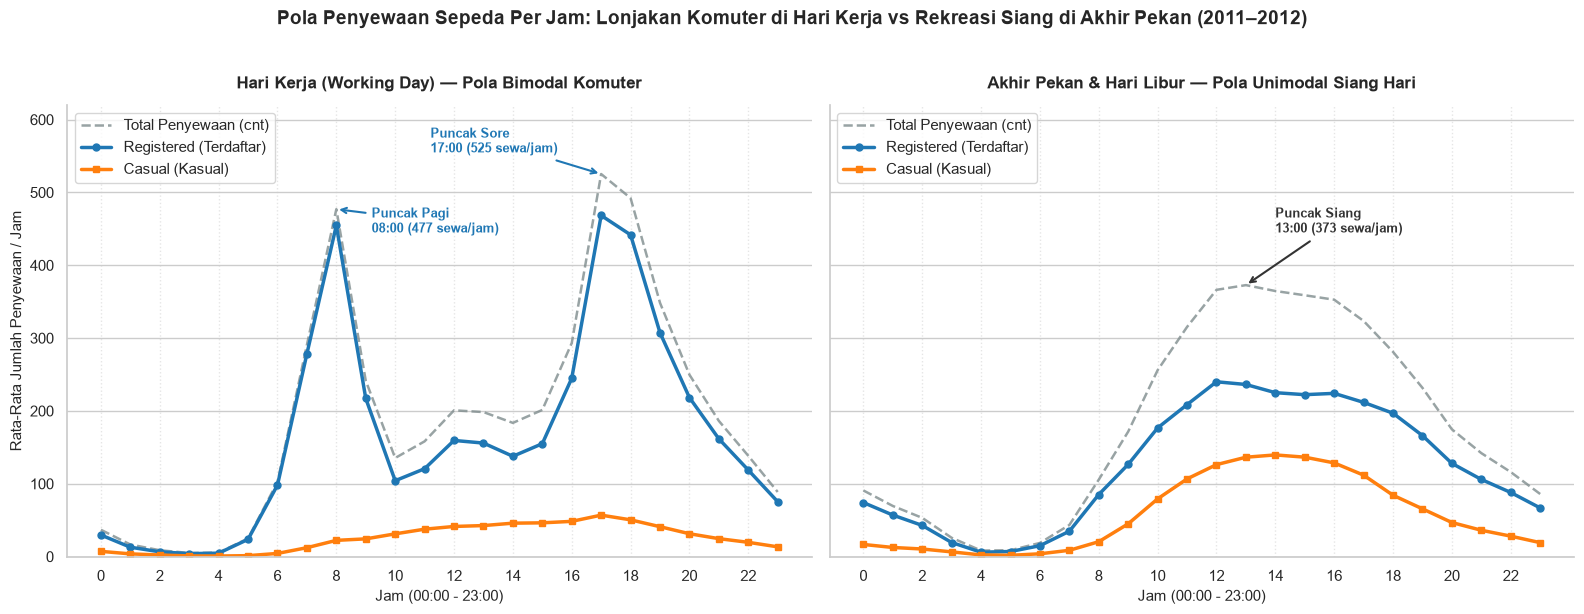

In [42]:
# Agregasi rata-rata penyewaan per jam berdasarkan kategori hari
hourly_agg = hour_df.groupby(["workingday", "hr"])[["casual", "registered", "cnt"]].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
fig.suptitle(
    "Pola Penyewaan Sepeda Per Jam: Lonjakan Komuter di Hari Kerja vs Rekreasi Siang di Akhir Pekan (2011–2012)",
    fontsize=14, fontweight="bold", y=1.02
)

categories = [
    ("Working Day", "Hari Kerja (Working Day) — Pola Bimodal Komuter"),
    ("Weekend/Holiday", "Akhir Pekan & Hari Libur — Pola Unimodal Siang Hari")
]

for ax, (cat, subtitle) in zip(axes, categories):
    subset = hourly_agg[hourly_agg["workingday"] == cat]
    
    ax.plot(subset["hr"], subset["cnt"], label="Total Penyewaan (cnt)", color="#7f8c8d", linestyle="--", linewidth=1.8, alpha=0.8)
    ax.plot(subset["hr"], subset["registered"], label="Registered (Terdaftar)", color="#1f77b4", marker="o", markersize=5, linewidth=2.5)
    ax.plot(subset["hr"], subset["casual"], label="Casual (Kasual)", color="#ff7f0e", marker="s", markersize=5, linewidth=2.5)
    
    ax.set_title(subtitle, fontsize=12, fontweight="bold", pad=12)
    ax.set_xlabel("Jam (00:00 - 23:00)", fontsize=11)
    ax.set_xticks(range(0, 24, 2))
    ax.set_ylim(0, 620)
    ax.grid(axis="x", linestyle=":", alpha=0.5)
    ax.legend(frameon=True, facecolor="white", loc="upper left")
    sns.despine(ax=ax)

axes[0].set_ylabel("Rata-Rata Jumlah Penyewaan / Jam", fontsize=11)

# Anotasi puncak pada Hari Kerja
axes[0].annotate(
    "Puncak Pagi\n08:00 (477 sewa/jam)",
    xy=(8, 477.01), xytext=(9.2, 445),
    arrowprops=dict(arrowstyle="->", color="#1f77b4", lw=1.5),
    fontsize=9.5, fontweight="bold", color="#1f77b4"
)
axes[0].annotate(
    "Puncak Sore\n17:00 (525 sewa/jam)",
    xy=(17, 525.29), xytext=(11.2, 555),
    arrowprops=dict(arrowstyle="->", color="#1f77b4", lw=1.5),
    fontsize=9.5, fontweight="bold", color="#1f77b4"
)

# Anotasi puncak pada Akhir Pekan/Hari Libur
axes[1].annotate(
    "Puncak Siang\n13:00 (373 sewa/jam)",
    xy=(13, 372.73), xytext=(14.0, 445),
    arrowprops=dict(arrowstyle="->", color="#333333", lw=1.5),
    fontsize=9.5, fontweight="bold", color="#333333"
)

plt.tight_layout()
plt.show()

### Pertanyaan 2:
#### Seberapa besar selisih dan persentase penurunan rata-rata volume penyewaan sepeda harian (`cnt`) akibat perubahan kondisi cuaca (*weathersit*) dan pergantian musim (*season*) sepanjang tahun 2011 hingga 2012?

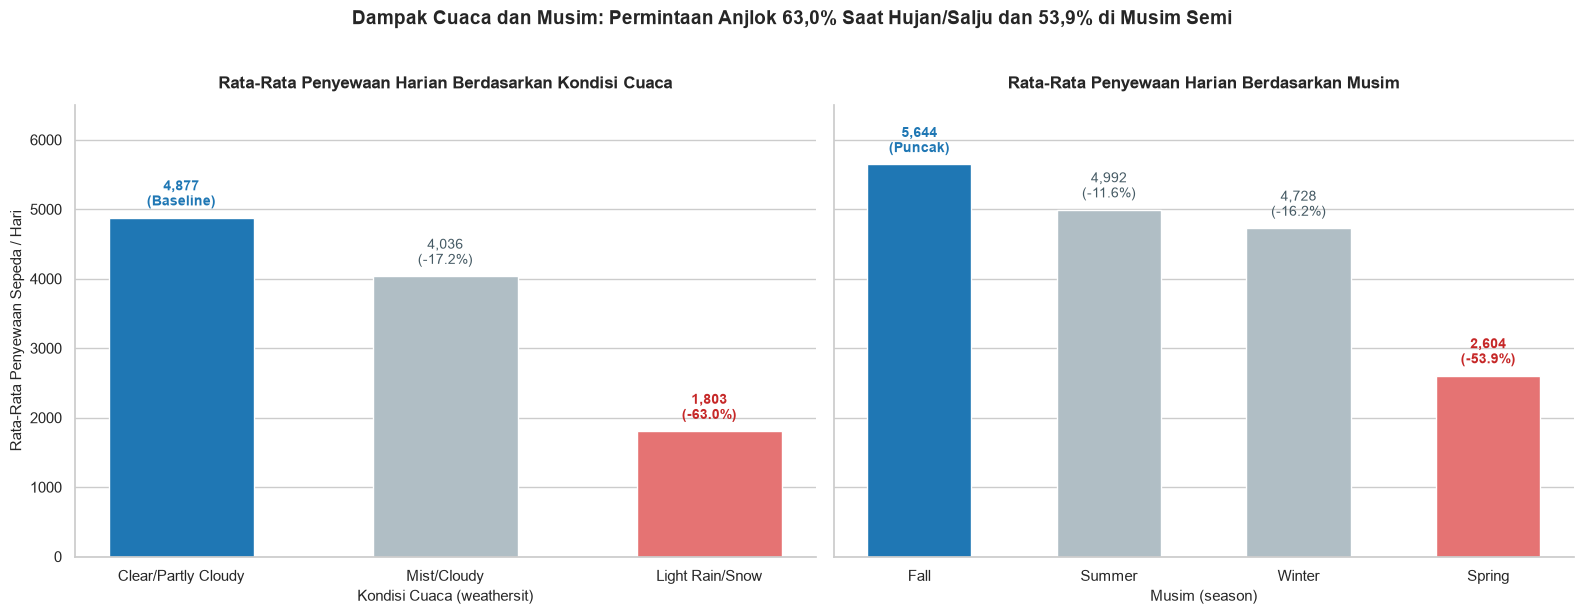

In [43]:
# Menyiapkan data rata-rata penyewaan harian berdasarkan kondisi cuaca dan musim
weather_order = ["Clear/Partly Cloudy", "Mist/Cloudy", "Light Rain/Snow"]
weather_df = day_df.groupby("weathersit")["cnt"].mean().reindex(weather_order).reset_index()
clear_val = weather_df.loc[0, "cnt"]

season_order = ["Fall", "Summer", "Winter", "Spring"]
season_df = day_df.groupby("season")["cnt"].mean().reindex(season_order).reset_index()
fall_val = season_df.loc[0, "cnt"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
fig.suptitle(
    "Dampak Cuaca dan Musim: Permintaan Anjlok 63,0% Saat Hujan/Salju dan 53,9% di Musim Semi",
    fontsize=14, fontweight="bold", y=1.02
)

# Panel Kiri: Kondisi Cuaca
weather_colors = ["#1f77b4", "#b0bec5", "#e57373"]
bars1 = axes[0].bar(weather_df["weathersit"], weather_df["cnt"], color=weather_colors, width=0.55)
axes[0].set_title("Rata-Rata Penyewaan Harian Berdasarkan Kondisi Cuaca", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xlabel("Kondisi Cuaca (weathersit)", fontsize=11)
axes[0].set_ylabel("Rata-Rata Penyewaan Sepeda / Hari", fontsize=11)
axes[0].set_ylim(0, 6500)
axes[0].grid(axis="x", visible=False)
sns.despine(ax=axes[0])

for i, bar in enumerate(bars1):
    val = bar.get_height()
    pct_diff = ((val - clear_val) / clear_val) * 100
    label_txt = f"{val:,.0f}\n(Baseline)" if i == 0 else f"{val:,.0f}\n({pct_diff:+.1f}%)"
    axes[0].text(
        bar.get_x() + bar.get_width() / 2, val + 120,
        label_txt, ha="center", va="bottom", fontsize=10,
        fontweight="bold" if i in [0, 2] else "normal",
        color="#1f77b4" if i == 0 else ("#c62828" if i == 2 else "#455a64")
    )

# Panel Kanan: Musim
season_colors = ["#1f77b4", "#b0bec5", "#b0bec5", "#e57373"]
bars2 = axes[1].bar(season_df["season"], season_df["cnt"], color=season_colors, width=0.55)
axes[1].set_title("Rata-Rata Penyewaan Harian Berdasarkan Musim", fontsize=12, fontweight="bold", pad=12)
axes[1].set_xlabel("Musim (season)", fontsize=11)
axes[1].grid(axis="x", visible=False)
sns.despine(ax=axes[1])

for i, bar in enumerate(bars2):
    val = bar.get_height()
    pct_diff = ((val - fall_val) / fall_val) * 100
    label_txt = f"{val:,.0f}\n(Puncak)" if i == 0 else f"{val:,.0f}\n({pct_diff:+.1f}%)"
    axes[1].text(
        bar.get_x() + bar.get_width() / 2, val + 120,
        label_txt, ha="center", va="bottom", fontsize=10,
        fontweight="bold" if i in [0, 3] else "normal",
        color="#1f77b4" if i == 0 else ("#c62828" if i == 3 else "#455a64")
    )

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
* **Visualisasi Pertanyaan 1 (Perilaku Komuter vs Rekreasi):** Grafik garis memperlihatkan perbedaan struktural yang tajam antara hari kerja dan akhir pekan. Pada **Working Day**, terjadi dua lonjakan tajam (*bimodal*) pada pukul **08.00** (477 sewa/jam) dan **17.00** (525 sewa/jam) yang hampir sepenuhnya didorong oleh pengguna `registered` (komuter berangkat dan pulang kerja). Sebaliknya, pada **Weekend/Holiday**, permintaan terkonsentrasi pada rentang rekreasi siang hari pukul **11.00–16.00** (puncak pukul **13.00** sebesar 373 sewa/jam) dengan lonjakan signifikan dari pengguna `casual` (mencapai ~140 sewa/jam pada pukul 14.00).
* **Visualisasi Pertanyaan 2 (Penurunan Akibat Cuaca Buruk & Musim Semi):** Grafik batang menunjukkan bahwa kondisi cuaca dan musim memengaruhi permintaan harian secara drastis. Dibandingkan kondisi cuaca cerah (`Clear/Partly Cloudy`: **4.877** sewa/hari), cuaca berkabut/berawan (`Mist/Cloudy`) menurunkan penyewaan sebesar **17,2%** (-841 sewa/hari), dan cuaca hujan ringan/salju (`Light Rain/Snow`) memangkas penyewaan hingga **63,0%** (-3.074 sewa/hari). Dari sisi musim, musim gugur (`Fall`: **5.644** sewa/hari) mencatat permintaan tertinggi, sedangkan musim semi (`Spring`: **2.604** sewa/hari) mengalami penurunan sebesar **53,9%** (-3.040 sewa/hari) dari puncak musim gugur.

## Analisis Lanjutan (Opsional)
Pada bagian **Analisis Lanjutan**, diterapkan teknik **Clustering tanpa algoritma Machine Learning** melalui dua pendekatan yang relevan dengan operasional penyewaan sepeda:
1. **Manual Grouping (Pengelompokan Berbasis Aturan Bisnis/Domain):** Membagi 24 jam operasional (`hr`) ke dalam 4 klaster periode aktivitas transportasi (*Morning Commute*, *Midday / Leisure*, *Evening Commute*, dan *Night / Off-Peak*) untuk memetakan kebutuhan distribusi armada berdasarkan segmen waktu.
2. **Binning (Pengelompokan Berbasis Interval/Kuantil):** Membagi total volume penyewaan harian (`cnt`) ke dalam 3 klaster tingkat permintaan (*Low Demand*, *Medium Demand*, dan *High Demand*) menggunakan metode kuantil (`pd.qcut`) untuk mengidentifikasi karakteristik lingkungan (suhu aktual dalam °C dan kelembapan udara) serta distribusi musim pada masing-masing klaster permintaan.

=== Tabel Ringkasan Manual Grouping (Klaster Waktu Operasional) ===


rata_rata_casual  \
workingday      time_cluster                                        
Weekend/Holiday Evening Commute\n(16:00-19:59)              97.60   
                Midday / Leisure\n(10:00-15:59)            120.78   
                Morning Commute\n(06:00-09:59)              19.50   
                Night / Off-Peak\n(20:00-05:59)             18.11   
Working Day     Evening Commute\n(16:00-19:59)              49.18   
                Midday / Leisure\n(10:00-15:59)             40.83   
                Morning Commute\n(06:00-09:59)              15.77   
                Night / Off-Peak\n(20:00-05:59)             10.63   

                                                 rata_rata_registered  \
workingday      time_cluster                                            
Weekend/Holiday Evening Commute\n(16:00-19:59)                 199.74   
                Midday / Leisure\n(10:00-15:59)                218.16   
                Morning Commute\n(06:00-09:59)                  65.50   
                Night / Off-Peak\n(20:00-05:59)                 59.81   
Working Day     Evening Commute\n(16:00-19:59)                 365.57   
                Midday / Leisure\n(10:00-15:59)                138.83   
                Morning Commute\n(06:00-09:59)                 262.14   
                Night / Off-Peak\n(20:00-05:59)                 66.47   

                                                 rata_rata_cnt  total_sewa  
workingday      time_cluster                                                
Weekend/Holiday Evening Commute\n(16:00-19:59)          297.34      274148  
                Midday / Leisure\n(10:00-15:59)         338.95      469779  
                Morning Commute\n(06:00-09:59)           85.00       78370  
                Night / Off-Peak\n(20:00-05:59)          77.92      177972  
Working Day     Evening Commute\n(16:00-19:59)          414.75      827021  
                Midday / Leisure\n(10:00-15:59)         179.66      535932  
                Morning Commute\n(06:00-09:59)          277.91      551372  
                Night / Off-Peak\n(20:00-05:59)          77.10      378085


=== Tabel Ringkasan Binning (Klaster Tingkat Permintaan Harian) ===


,jumlah_hari,rata_rata_cnt,rata_rata_temp_c,rata_rata_hum_pct,rata_rata_casual,rata_rata_registered
demand_cluster,,,,,,
Low Demand\n(22–3.740),244,2312.07,13.67,63.57,333.38,1978.68
Medium Demand\n(3.744–5.312),244,4522.23,22.89,64.61,842.96,3679.26
High Demand\n(5.315–8.714),243,6687.70,24.38,60.54,1370.33,5317.38



=== Proporsi Klaster Permintaan di Setiap Musim (%) ===


demand_cluster,Low Demand\n(22–3.740),Medium Demand\n(3.744–5.312),High Demand\n(5.315–8.714)
season,,,
Fall,6.9,42.0,51.1
Spring,77.3,18.2,4.4
Summer,20.1,38.6,41.3
Winter,30.3,34.3,35.4


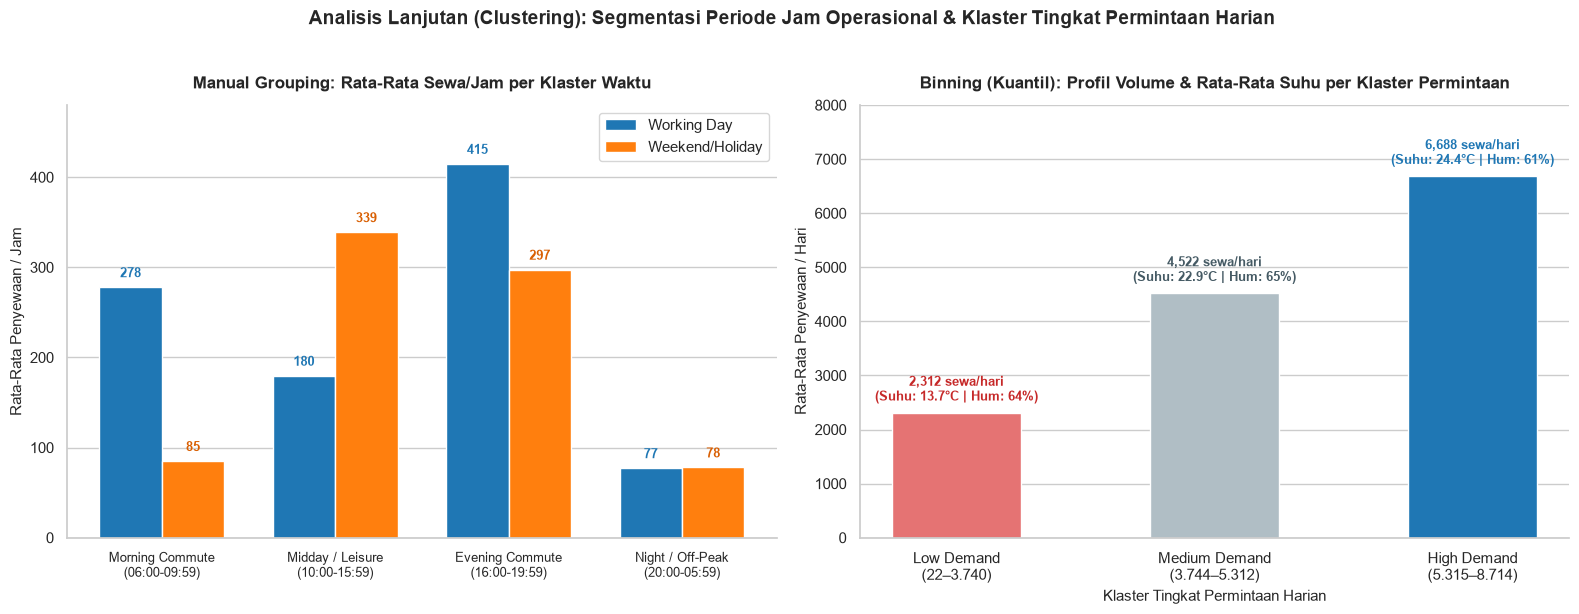

In [44]:
# 1. Clustering dengan Manual Grouping: Segmentasi Periode Waktu Operasional
def categorize_time_period(hr):
    if 6 <= hr <= 9:
        return "Morning Commute\n(06:00-09:59)"
    elif 10 <= hr <= 15:
        return "Midday / Leisure\n(10:00-15:59)"
    elif 16 <= hr <= 19:
        return "Evening Commute\n(16:00-19:59)"
    else:
        return "Night / Off-Peak\n(20:00-05:59)"

hour_df["time_cluster"] = hour_df["hr"].apply(categorize_time_period)

time_cluster_summary = hour_df.groupby(["workingday", "time_cluster"]).agg(
    rata_rata_casual=("casual", "mean"),
    rata_rata_registered=("registered", "mean"),
    rata_rata_cnt=("cnt", "mean"),
    total_sewa=("cnt", "sum")
).round(2)

print("=== Tabel Ringkasan Manual Grouping (Klaster Waktu Operasional) ===")
display(time_cluster_summary)

# 2. Clustering dengan Binning: Segmentasi Tingkat Permintaan Harian
day_df["demand_cluster"] = pd.qcut(
    day_df["cnt"],
    q=3,
    labels=["Low Demand\n(22–3.740)", "Medium Demand\n(3.744–5.312)", "High Demand\n(5.315–8.714)"]
)

demand_cluster_summary = day_df.groupby("demand_cluster", observed=False).agg(
    jumlah_hari=("cnt", "count"),
    rata_rata_cnt=("cnt", "mean"),
    rata_rata_temp_c=("temp", lambda x: (x * 41).mean()),   # Konversi nilai ternormalisasi ke Celcius (skala maks 41°C)
    rata_rata_hum_pct=("hum", lambda x: (x * 100).mean()),   # Konversi nilai ternormalisasi ke persen (%)
    rata_rata_casual=("casual", "mean"),
    rata_rata_registered=("registered", "mean")
).round(2)

print("\n=== Tabel Ringkasan Binning (Klaster Tingkat Permintaan Harian) ===")
display(demand_cluster_summary)

# Proporsi musim pada setiap klaster permintaan (%)
season_demand_ct = (pd.crosstab(day_df["season"], day_df["demand_cluster"], normalize="index") * 100).round(1)
print("\n=== Proporsi Klaster Permintaan di Setiap Musim (%) ===")
display(season_demand_ct)

# 3. Visualisasi Hasil Clustering (Manual Grouping & Binning)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(
    "Analisis Lanjutan (Clustering): Segmentasi Periode Jam Operasional & Klaster Tingkat Permintaan Harian",
    fontsize=14, fontweight="bold", y=1.02
)

# Panel Kiri: Manual Grouping
cluster_order = [
    "Morning Commute\n(06:00-09:59)",
    "Midday / Leisure\n(10:00-15:59)",
    "Evening Commute\n(16:00-19:59)",
    "Night / Off-Peak\n(20:00-05:59)"
]
plot_tc = hour_df.groupby(["time_cluster", "workingday"])["cnt"].mean().unstack().reindex(cluster_order)

x = np.arange(len(cluster_order))
width = 0.36
rects1 = axes[0].bar(x - width/2, plot_tc["Working Day"], width, label="Working Day", color="#1f77b4")
rects2 = axes[0].bar(x + width/2, plot_tc["Weekend/Holiday"], width, label="Weekend/Holiday", color="#ff7f0e")

axes[0].set_title("Manual Grouping: Rata-Rata Sewa/Jam per Klaster Waktu", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xticks(x)
axes[0].set_xticklabels(cluster_order, fontsize=9.5)
axes[0].set_ylabel("Rata-Rata Penyewaan / Jam", fontsize=11)
axes[0].set_ylim(0, 480)
axes[0].grid(axis="x", visible=False)
axes[0].legend(frameon=True, facecolor="white", loc="upper right")
sns.despine(ax=axes[0])

for rect in rects1:
    h = rect.get_height()
    axes[0].text(rect.get_x() + rect.get_width()/2, h + 8, f"{h:.0f}", ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#1f77b4")
for rect in rects2:
    h = rect.get_height()
    axes[0].text(rect.get_x() + rect.get_width()/2, h + 8, f"{h:.0f}", ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#d95f02")

# Panel Kanan: Binning
dc_plot = demand_cluster_summary.reset_index()
dc_colors = ["#e57373", "#b0bec5", "#1f77b4"]
bars_dc = axes[1].bar(dc_plot["demand_cluster"], dc_plot["rata_rata_cnt"], color=dc_colors, width=0.5)

axes[1].set_title("Binning (Kuantil): Profil Volume & Rata-Rata Suhu per Klaster Permintaan", fontsize=12, fontweight="bold", pad=12)
axes[1].set_xlabel("Klaster Tingkat Permintaan Harian", fontsize=11)
axes[1].set_ylabel("Rata-Rata Penyewaan / Hari", fontsize=11)
axes[1].set_ylim(0, 8000)
axes[1].grid(axis="x", visible=False)
sns.despine(ax=axes[1])

for i, bar in enumerate(bars_dc):
    h = bar.get_height()
    temp_c = dc_plot.loc[i, "rata_rata_temp_c"]
    hum_pct = dc_plot.loc[i, "rata_rata_hum_pct"]
    axes[1].text(
        bar.get_x() + bar.get_width()/2, h + 150,
        f"{h:,.0f} sewa/hari\n(Suhu: {temp_c:.1f}°C | Hum: {hum_pct:.0f}%)",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold",
        color="#c62828" if i == 0 else ("#1f77b4" if i == 2 else "#455a64")
    )

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
* **Hasil Manual Grouping (Pergeseran Klaster Waktu):** Pada **Working Day**, klaster *Evening Commute (16:00–19:59)* menempati posisi tertinggi dengan rata-rata **415 sewa/jam** (total 827.021 sewa), diikuti *Morning Commute (06:00–09:59)* sebesar **278 sewa/jam**. Sebaliknya, pada **Weekend/Holiday**, aktivitas komuter pagi turun drastis menjadi **85 sewa/jam** dan berpindah ke klaster *Midday / Leisure (10:00–15:59)* sebagai klaster tertinggi dengan rata-rata **339 sewa/jam**. Sementara itu, klaster *Night / Off-Peak (20:00–05:59)* konsisten menjadi periode paling lengang di kedua jenis hari (~77–78 sewa/jam) sehingga ideal untuk jadwal rotasi dan pengisian ulang unit sepeda di lapangan.
* **Hasil Binning (Profil Suhu & Musim pada Klaster Permintaan):** Klaster *High Demand* (5.315–8.714 sewa/hari; rata-rata **6.688 sewa/hari**) terjadi pada hari-hari dengan suhu udara hangat (rata-rata **24,4°C**) dan kelembapan sedang (**61%**), di mana **51,1%** hari di musim gugur (`Fall`) dan **41,3%** hari di musim panas (`Summer`) masuk dalam kategori ini. Sebaliknya, klaster *Low Demand* (22–3.740 sewa/hari; rata-rata **2.312 sewa/hari**) didominasi oleh cuaca dingin dengan rata-rata suhu **13,7°C**, yang mencakup **77,3%** dari keseluruhan hari di musim semi (`Spring`).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pola penyewaan sepeda per jam menunjukkan perbedaan struktur permintaan yang kontras antara hari kerja dan akhir pekan/hari libur, di mana secara keseluruhan pengguna terdaftar (`registered`) mendominasi **81,17%** total penyewaan (2.672.662 sewa) dibandingkan pengguna kasual (`casual`) sebesar **18,83%** (620.017 sewa). Pada **Working Day**, permintaan membentuk pola dua puncak (*bimodal*) yang digerakkan oleh komuter terdaftar, yakni pada pukul **08.00** (rata-rata **477,01** sewa/jam) dan pukul **17.00–18.00** (masing-masing **525,29** dan **492,23** sewa/jam; klaster *Evening Commute* menjadi periode tersibuk dengan rata-rata 414,75 sewa/jam). Sebaliknya, pada **Weekend/Holiday**, permintaan bergeser menjadi satu kurva siang hari (*unimodal*) pada klaster *Midday/Leisure* (pukul **10.00–15.59**) dengan puncak pada pukul **13.00** (rata-rata **372,73** sewa/jam), disertai lonjakan penggunaan segmen `casual` hingga lebih dari dua kali lipat dibandingkan hari kerja.

- **Conclusion pertanyaan 2:** Kondisi cuaca dan pergantian musim terbukti memberikan dampak penurunan yang signifikan terhadap volume penyewaan sepeda harian (`cnt`). Dibandingkan cuaca cerah (`Clear/Partly Cloudy`) yang mencatat rata-rata **4.876,79** sewa/hari, cuaca berkabut/berawan (`Mist/Cloudy`) menurunkan permintaan sebesar **17,24%** (-840,92 sewa/hari menjadi 4.035,86 sewa/hari), sedangkan hujan ringan/salju (`Light Rain/Snow`) memangkas penyewaan hingga **63,02%** (-3.073,50 sewa/hari menjadi 1.803,29 sewa/hari). Dari sisi musim, musim gugur (`Fall`) menjadi puncak permintaan tertinggi (**5.644,30** sewa/hari; 51,1% harinya masuk klaster *High Demand* dengan rata-rata suhu 24,4°C), sementara musim semi (`Spring`) mencatat volume terendah (**2.604,13** sewa/hari) atau turun sebesar **53,86%** (-3.040,17 sewa/hari) dari puncak musim gugur.

**Rekomendasi Action Item:**
- **Optimalisasi Jadwal Distribusi Armada (*Rebalancing*) Berbasis Klaster Waktu:** Tim operasional lapangan perlu melakukan distribusi ulang (*rebalancing*) sepeda ke stasiun dekat kawasan permukiman dan transit transportasi umum sebelum pukul **07.00** serta ke kawasan perkantoran sebelum pukul **16.00** pada hari kerja (`Working Day`), sekaligus memindahkan fokus ketersediaan unit ke area taman, pusat kota, dan destinasi wisata menjelang pukul **10.00** pada akhir pekan (`Weekend/Holiday`). Seluruh proses pengisian ulang dan inspeksi ringan harian sebaiknya dijadwalkan pada klaster *Night / Off-Peak* (pukul **20.00–05.59**) saat permintaan berada di titik terendah (~77 sewa/jam).
- **Konversi Pengguna Kasual Menjadi Pelanggan Terdaftar di Akhir Pekan:** Tim pemasaran dapat meluncurkan promo keanggotaan (*membership*) khusus akhir pekan atau paket *bundling* perjalanan siang hari (pukul **11.00–16.00**) yang menyasar pengguna `casual` pada hari libur/akhir pekan guna mendorong konversi mereka menjadi pengguna `registered` yang memiliki frekuensi penggunaan rutin.
- **Penjadwalan Pemeliharaan Besar (*Major Maintenance*) & Penyesuaian Kapasitas Musiman:** Tim teknis dan pemeliharaan disarankan memusatkan jadwal servis besar, perbaikan komponen, serta peremajaan armada pada musim semi (`Spring`) dan saat prakiraan cuaca menunjukkan hujan ringan/salju (`Light Rain/Snow`), karena volume permintaan turun lebih dari 50–63% sehingga tidak mengganggu ketersediaan layanan. Sebaliknya, seluruh armada harus dalam kondisi kesiapan 100% memasuki musim panas (`Summer`) hingga puncak musim gugur (`Fall`).